### Module 3 — Supervised Learning: Classification
### Judging a classifier

---
On Tuesday we built a classifier and it scored **89% accuracy** while finding
almost no goals at all. Today we will try to fix that issue by using the right metrics to judging a classifier.


**Outline:**

1. Evaluating classification: the confusion matrix, precision, recall, F1, ROC-AUC
2. When the thing you care about is rare: imbalanced data and what to do about it

In [9]:
# setup
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                             f1_score, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)
plt.rcParams["figure.dpi"] = 110

### What we have been doing

---

Let us rebuild Tuesday's model in one cell — same data, same two features,
same split — so we have something concrete to judge.

In [23]:
shots = pd.read_csv("https://raw.githubusercontent.com/sparks5969/course-advanced-data-analysis/main/shots_statsbomb.csv")

train, test = train_test_split(shots, test_size=0.2, random_state=42, stratify=shots.goal)
FEATURES = ["distance", "angle"]
model = make_pipeline(StandardScaler(), LogisticRegression()).fit(train[FEATURES], train.goal)

test = test.copy()
test["our_p"] = model.predict_proba(test[FEATURES])[:, 1]
decisions = (test.our_p >= 0.5).astype(int)

print(f"test shots: {len(test)}   |   goals among them: {int(test.goal.sum())}")
print(f"accuracy at threshold 0.5 : {(decisions == test.goal).mean():.4f}")
print(f"'never a goal' accuracy   : {(test.goal == 0).mean():.4f}")
print(f"goals found               : {int(((decisions==1) & (test.goal==1)).sum())} of {int(test.goal.sum())}")

test shots: 567   |   goals among them: 64
accuracy at threshold 0.5 : 0.8889
'never a goal' accuracy   : 0.8871
goals found               : 1 of 64


Accuracy is a single number, and a single number cannot tell you *which*
mistakes a model made. We need to separate the kinds of error.

### The fit, in one picture

---

Before we judge the model, look at what a logistic fit *is*. To draw it on one
axis we use **distance alone**, with the sign flipped so moving **right means
moving toward the goal**.
Note: one deliberate cheat for this picture only: the real data is 89% no-goals,
and that squashes the fitted curve to the floor — on the full data it never
reaches 0.5, peaking at 0.49 right on the goal line. So here we take **every
goal and an equal number of non-goals**, and refit. That is what makes the
S-shape visible. It is a demonstration of the shape, not the model we use
anywhere else today.


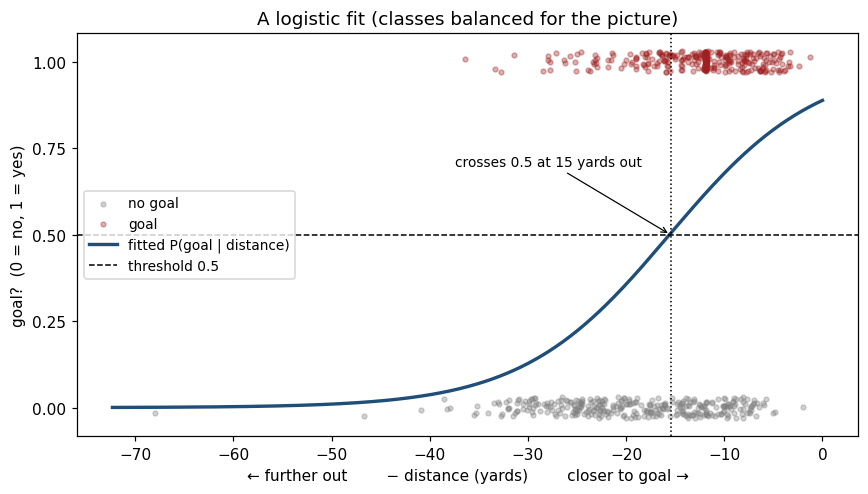

321 goals + 321 non-goals; the curve crosses 0.5 at 15.5 yards
(on the real 11%-goal data the same curve never reaches 0.5)


In [25]:
goals_all = shots[shots.goal == 1]
balanced  = pd.concat([goals_all,
                       shots[shots.goal == 0].sample(len(goals_all), random_state=0)])
demo_fit  = LogisticRegression().fit(balanced[["distance"]], balanced.goal)

d_grid = np.linspace(0, shots.distance.max(), 300)
p_grid = demo_fit.predict_proba(pd.DataFrame({"distance": d_grid}))[:, 1]
cross  = d_grid[np.argmin(np.abs(p_grid - 0.5))]         # where the curve passes 0.5

rng    = np.random.default_rng(0)
jitter = rng.uniform(-0.03, 0.03, len(balanced))         # spread the dots so density shows

plt.figure(figsize=(8, 4.6))
for cls, colour, label in [(0, "gray", "no goal"), (1, "#a02020", "goal")]:
    m = (balanced.goal == cls).values
    plt.scatter(-balanced.distance[m], cls + jitter[m], s=10, alpha=0.35, color=colour, label=label)
plt.plot(-d_grid, p_grid, color="#1f4e79", lw=2.2, label="fitted P(goal | distance)")
plt.axhline(0.5, color="k", ls="--", lw=1, label="threshold 0.5")
plt.axvline(-cross, color="k", ls=":", lw=1)
plt.annotate(f"crosses 0.5 at {cross:.0f} yards out",
             xy=(-cross, 0.5), xytext=(-cross - 22, 0.7), fontsize=9,
             arrowprops=dict(arrowstyle="->", color="k", lw=0.8))
plt.xlabel("← further out        − distance (yards)        closer to goal →")
plt.ylabel("goal?  (0 = no, 1 = yes)")
plt.yticks([0, 0.25, 0.5, 0.75, 1])
plt.title("A logistic fit (classes balanced for the picture)")
plt.legend(loc="center left", fontsize=9); plt.tight_layout(); plt.show()

print(f"{len(goals_all)} goals + {len(goals_all)} non-goals; the curve crosses 0.5 at {cross:.1f} yards")
print("(on the real 11%-goal data the same curve never reaches 0.5)")


### The confusion matrix

---

Every prediction on a 0/1 label falls into exactly one of four boxes.

In [26]:
cm = confusion_matrix(test.goal, decisions)
tn, fp, fn, tp = cm.ravel()

table = pd.DataFrame(
    [[f"TN = {tn}", f"FP = {fp}"],
     [f"FN = {fn}", f"TP = {tp}"]],
    index   = ["actually NO goal", "actually a GOAL"],
    columns = ["we said no goal", "we said GOAL"])
print(table.to_string())

print(f"\nthe model said 'GOAL' {tp + fp} times out of {len(test)} shots")

                 we said no goal we said GOAL
actually NO goal        TN = 503       FP = 0
actually a GOAL          FN = 63       TP = 1

the model said 'GOAL' 1 times out of 567 shots


### In general:

---

Strip the numbers out and the four boxes have names. Rows are what *actually*
happened; columns are what the model *said*.

<table style="border-collapse:collapse; margin:18px auto; text-align:center;">
<tr>
  <td></td><td></td>
  <td colspan="2" style="padding:6px 14px; font-weight:bold; color:#1f4e79; font-size:14px;">the model said …</td>
</tr>
<tr>
  <td></td><td></td>
  <td style="padding:8px 14px; font-size:14px;"><b>no goal</b></td>
  <td style="padding:8px 14px; font-size:14px;"><b>GOAL</b></td>
</tr>
<tr>
  <td rowspan="2" style="padding:6px 10px; font-weight:bold; color:#1f4e79; font-size:14px;">it actually<br>was …</td>
  <td style="padding:8px 14px; font-size:14px;"><b>no goal</b></td>
  <td  style="padding:16px 26px; border:1px solid #bbb; font-size:15px; background:#dff0df;"><b>TN</b><br><span style="font-size:12px;">true negative</span></td>
  <td  style="padding:16px 26px; border:1px solid #bbb; font-size:15px; background:#f8dcdc;"><b>FP</b><br><span style="font-size:12px;">false positive<br><i>a false alarm</i></span></td>
</tr>
<tr>
  <td style="padding:8px 14px; font-size:14px;"><b>GOAL</b></td>
  <td  style="padding:16px 26px; border:1px solid #bbb; font-size:15px; background:#f8dcdc;"><b>FN</b><br><span style="font-size:12px;">false negative<br><i>a miss</i></span></td>
  <td  style="padding:16px 26px; border:1px solid #bbb; font-size:15px; background:#dff0df;"><b>TP</b><br><span style="font-size:12px;">true positive</span></td>
</tr>
</table>

- **The diagonal** (green) is where we were right. **Off the diagonal** (red) is where we were wrong — and those are two *different* mistakes, which is the whole point.
- **True / false** says whether the model was right. **Positive / negative** says what the model *said* — so a false positive is a wrong "goal", a false negative is a wrong "no goal".
- This is the same orientation `sklearn`'s `confusion_matrix` uses: negatives first, so it returns `[[TN, FP], [FN, TP]]` — exactly the layout printed above.


Read the four boxes carefully, because every metric today is built from them:

| | meaning | football | the cost |
|---|---|---|---|
| **TP** | we said goal, it was a goal | a chance correctly identified | — |
| **TN** | we said no goal, it was not | correctly ignored | — |
| **FP** | we said goal, it was not | a **false alarm** | we waste attention |
| **FN** | we said no goal, but it was | a **miss** | the thing we cared about slipped past |

You might have met these
before under different names. A **false positive is a Type I error** — rejecting
a true null, claiming an effect that is not there. A **false negative is a Type
II error** — failing to detect something real. The confusion matrix is the same
two errors, counted on held-out data instead of assumed under a distribution.

<p align="center">
<img src="https://raw.githubusercontent.com/sparks5969/course-advanced-data-analysis/main/type1type2_goals.png" width="680">
</p>

The dashed line is the threshold. Slide it to the right and the blue area (α, shots we wrongly call goals) shrinks while the orange area (β, goals we fail to call) grows — the trade we are about to make explicit.

### The metrics — all built from the four boxes

---

Accuracy mixes all four boxes into one number. The others keep them apart,
and each one answers a different question:

| metric | formula | the question it answers | what it ignores |
|---|---|---|---|
| **Accuracy** | (TP + TN) / all | how often are we right? | *which* mistake we made |
| **Precision** | TP / (TP + FP) | of the shots we *called* goals, how many were? | the goals we missed (FN) |
| **Recall** — a.k.a. sensitivity, true positive rate | TP / (TP + FN) | of the goals that *happened*, how many did we find? | the false alarms (FP) |
| **Specificity** — true negative rate | TN / (TN + FP) | of the non-goals, how many did we correctly leave alone? | everything about the goals |
| **False positive rate** | FP / (FP + TN) = 1 − specificity | of the non-goals, how many did we wrongly flag? | — *(this will be the x-axis of the ROC curve)* |
| **F1** | 2·P·R / (P + R) | precision and recall at once — their harmonic mean | TN entirely |


In [14]:
n = len(test)
acc  = (tp + tn) / n
prec = precision_score(test.goal, decisions, zero_division=0)
rec  = recall_score(test.goal, decisions)
spec = tn / (tn + fp)
fpr  = fp / (fp + tn)
f1   = f1_score(test.goal, decisions)

print(f"accuracy    = (TP + TN) / all   = ({tp} + {tn}) / {n} = {acc:.3f}")
print(f"precision   = TP / (TP + FP)    = {tp} / {tp + fp}       = {prec:.3f}   of the shots we CALLED goals, how many were?")
print(f"recall (a.k.a. sensitivity)      = TP / (TP + FN)    = {tp} / {tp + fn}      = {rec:.3f}   of the goals that HAPPENED, how many did we find?")
print(f"specificity = TN / (TN + FP)    = {tn} / {tn + fp}   = {spec:.3f}   of the non-goals, how many did we leave alone?")
print(f"FPR         = FP / (FP + TN)    = {fp} / {fp + tn}     = {fpr:.3f}   of the non-goals, how many did we wrongly flag?")
print(f"F1          = 2PR / (P + R)                   = {f1:.3f}   precision and recall, together")


accuracy    = (TP + TN) / all   = (1 + 503) / 567 = 0.889
precision   = TP / (TP + FP)    = 1 / 1       = 1.000   of the shots we CALLED goals, how many were?
recall (a.k.a. sensitivity)      = TP / (TP + FN)    = 1 / 64      = 0.016   of the goals that HAPPENED, how many did we find?
specificity = TN / (TN + FP)    = 503 / 503   = 1.000   of the non-goals, how many did we leave alone?
FPR         = FP / (FP + TN)    = 0 / 503     = 0.000   of the non-goals, how many did we wrongly flag?
F1          = 2PR / (P + R)                   = 0.031   precision and recall, together


<span style="color:#a02020">**Look at what just happened.**</span> Our precision
is a perfect **1.000** — every single time the model said "goal", it was right.
By that measure it is flawless.

And it is useless...

That is the trade in its purest form:

- **Precision** punishes false alarms. You maximise it by only speaking when certain.
- **Recall** punishes misses. You maximise it by shouting "goal!" at everything.
- **F1** refuses to let you win by ignoring one of them — the harmonic mean collapses if either is near zero.

Accuracy of 0.889 told us the model was fine. Recall of 0.016 tells us it found
one goal in sixty-four.

### Pick a threshold with the appropriate metrics

---

Nothing about the *model* changes below. Only the cutoff we apply to its
probabilities — the choice Tuesday said belongs to the analyst.

In [29]:
rows = []
for t in [0.50, 0.30, 0.20, 0.15, 0.10, 0.07, 0.05]:
    d = (test.our_p >= t).astype(int)
    rows.append({
        "threshold": t,
        "flagged":   int(d.sum()),
        "TP":        int(((d==1) & (test.goal==1)).sum()),
        "FP":        int(((d==1) & (test.goal==0)).sum()),
        "precision": precision_score(test.goal, d, zero_division=0),
        "recall":    recall_score(test.goal, d),
        "F1":        f1_score(test.goal, d),
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))

 threshold  flagged  TP  FP  precision  recall    F1
      0.50        1   1   0      1.000   0.016 0.031
      0.30       23  10  13      0.435   0.156 0.230
      0.20       80  19  61      0.238   0.297 0.264
      0.15      155  40 115      0.258   0.625 0.365
      0.10      242  48 194      0.198   0.750 0.314
      0.07      314  56 258      0.178   0.875 0.296
      0.05      384  58 326      0.151   0.906 0.259


One model, seven different classifiers:

- At **0.50** we are silent and precise.
- At **0.15** we find **40 of 64** goals, at the price of 115 false alarms — and F1 peaks.
- At **0.05** we find **58 of 64**, but we are now calling 384 of 567 shots "goals", which is barely a prediction at all.

<span style="color:#1f4e79">**There is no "correct" row.**</span> There is only
the row that matches what each mistake costs you — and the data cannot tell you
that--- How costly if I made a mistake in my guess?

### ROC-AUC: judging every threshold at once

---

If the threshold is a choice, we can judge the *model* by how well it does
across all of them. That is the ROC curve — and the area under it (AUC) is one
number for the whole sweep. AUC = 0.5 is coin-flipping; AUC = 1.0 is perfect.

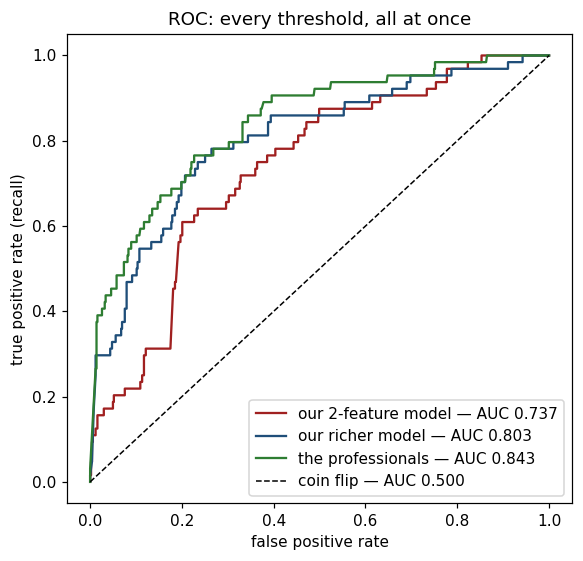

In [16]:
RICH = ["distance", "angle", "under_pressure", "first_time"]
Xtr = pd.get_dummies(train[RICH + ["body_part", "play_type"]], drop_first=True)
Xte = pd.get_dummies(test[RICH + ["body_part", "play_type"]], drop_first=True).reindex(
          columns=Xtr.columns, fill_value=0)
rich = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xtr, train.goal)
test["rich_p"] = rich.predict_proba(Xte)[:, 1]

plt.figure(figsize=(5.4, 5.2))
for col, label, colour in [("our_p", "our 2-feature model", "#a02020"),
                           ("rich_p", "our richer model", "#1f4e79"),
                           ("statsbomb_xg", "the professionals", "#2e7d32")]:
    fpr, tpr, _ = roc_curve(test.goal, test[col])
    plt.plot(fpr, tpr, color=colour,
             label=f"{label} — AUC {roc_auc_score(test.goal, test[col]):.3f}")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="coin flip — AUC 0.500")
plt.xlabel("false positive rate"); plt.ylabel("true positive rate (recall)")
plt.title("ROC: every threshold, all at once"); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

Three curves, three models, one picture. The ordering is exactly what Tuesday
predicted: two features < our richer model < the professionals.

Notice what AUC did for us that accuracy could not — it **ranked** the models
honestly, because it never committed to a threshold. Notice also what it still
hides: it says nothing about what happens at the threshold you actually ship.

### 8 · When the thing you care about is genuinely rare

---

Our shots were 11% goals. That was enough to embarrass accuracy. Now go to a
problem where the positive class is **one in two hundred** — real credit-card
transactions, where a handful are fraudulent and the rest are someone's grocery
run.

Two honest notes about this data before we use it:

- The features are called `V1`–`V28` because the bank would not publish what they are; they are principal components of the original variables. **That is fine today** — we are learning to *judge* a classifier, not to interpret one. Nothing below depends on knowing what `V14` means.
- The data comes from a Worldline / ULB Machine Learning Group collaboration on fraud detection.
- The real file is 284,807 transactions with a 0.172% fraud rate. This is a **classroom subsample**: every one of the 492 frauds is kept, and the legitimate transactions are thinned to 98,000, which lifts the rate to 0.50%. That makes the file load in seconds and leaves enough frauds to measure. It also makes the problem *easier* than reality — worth remembering.

In [17]:
fraud = pd.read_csv("https://raw.githubusercontent.com/sparks5969/course-advanced-data-analysis/main/creditcard_fraud_sample.csv.gz")

n_fraud = int(fraud.Class.sum())
rate    = fraud.Class.mean()
print(f"transactions : {len(fraud):,}")
print(f"frauds       : {n_fraud:,}  ({100*rate:.3f}% of all transactions)")
print(f"\n'there is never any fraud' accuracy: {100*(1-rate):.2f}%")
print(f"   ...and it catches 0 of {n_fraud} frauds.")
fraud[["V1", "V2", "V14", "Amount", "Class"]].head(3)

transactions : 98,492
frauds       : 492  (0.500% of all transactions)

'there is never any fraud' accuracy: 99.50%
   ...and it catches 0 of 492 frauds.


,V1,V2,V14,Amount,Class
0,1.482200,-0.197367,-0.204947,15.00,0
1,-1.707740,-0.351156,0.010577,100.00,0
2,-0.554478,0.930219,-0.790038,0.99,0


<span style="color:#a02020; font-size:17px">**A model that does nothing scores
99.50%.**</span>

On Tuesday the do-nothing baseline was 88.7% and we called it embarrassing.
Here it is so high that there is almost no room left above it. Watch what that
does to accuracy as a way of telling models apart.

### Fit the model

---

In [30]:
X = fraud.drop(columns=["Class"])
y = fraud.Class

Xtr_f, Xte_f, ytr_f, yte_f = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clf.fit(Xtr_f, ytr_f)
p_fraud = clf.predict_proba(Xte_f)[:, 1]
d_fraud = (p_fraud >= 0.5).astype(int)

print(f"our model's accuracy      : {(d_fraud == yte_f).mean():.4f}")
print(f"'never any fraud' accuracy: {(yte_f == 0).mean():.4f}")
print(f"difference                : {((d_fraud == yte_f).mean() - (yte_f == 0).mean())*100:.2f} percentage points")

our model's accuracy      : 0.9984
'never any fraud' accuracy: 0.9950
difference                : 0.34 percentage points


<span style="color:#1f4e79; font-size:17px">**Three tenths of a percentage
point.**</span>

That is the entire visible difference between a model that catches most of the
fraud and a model that has never heard of fraud. If accuracy were your
scoreboard, you could not tell them apart — and you would have no idea which
one to deploy.

Accuracy has not merely become a weak metric here. It has stopped carrying
information at all.

### What the model actually did

---

Open the four boxes instead.

In [31]:
cm_f = confusion_matrix(yte_f, d_fraud)
tn_f, fp_f, fn_f, tp_f = cm_f.ravel()

print(f"frauds in the test set : {int(yte_f.sum())}")
print(f"  caught (TP)          : {tp_f}")
print(f"  missed (FN)          : {fn_f}")
print(f"false alarms (FP)      : {fp_f}")
print(f"\nprecision {precision_score(yte_f, d_fraud, zero_division=0):.3f}"
      f" | recall {recall_score(yte_f, d_fraud):.3f}"
      f" | F1 {f1_score(yte_f, d_fraud):.3f}")

frauds in the test set : 148
  caught (TP)          : 113
  missed (FN)          : 35
false alarms (FP)      : 12

precision 0.904 | recall 0.764 | F1 0.828


This is a **good** model. Nine out of ten alerts are real fraud, and it finds
roughly three quarters of everything. Accuracy could not show you any of that;
precision and recall show it immediately.

So the lesson is not "the model is secretly terrible". It is that **accuracy
could not tell you either way**.

### One more trap: ROC-AUC flatters rare-class problems

---

In [32]:
ap = average_precision_score(yte_f, p_fraud)
print(f"ROC-AUC             : {roc_auc_score(yte_f, p_fraud):.4f}")
print(f"precision-recall AUC: {ap:.4f}")

ROC-AUC             : 0.9712
precision-recall AUC: 0.8156


Both are legitimate numbers, but they are not equally honest here, and the gap
is not noise.

The false-positive *rate* inside ROC divides by the number of legitimate
transactions — a denominator of nearly 30,000. A thousand extra false alarms
barely moves it. Precision divides by the number of alerts you actually raised,
which is in the hundreds. The same thousand false alarms wrecks it.

<span style="color:#1f4e79">**Rule of thumb:**</span> when the positive class is
rare, quote the **precision-recall** curve. ROC is the number that gets put in
slide decks; PR is the number the investigator lives with.

### The same model, drawn two ways

---

Left: what ROC says about it. Right: what an investigator would see.

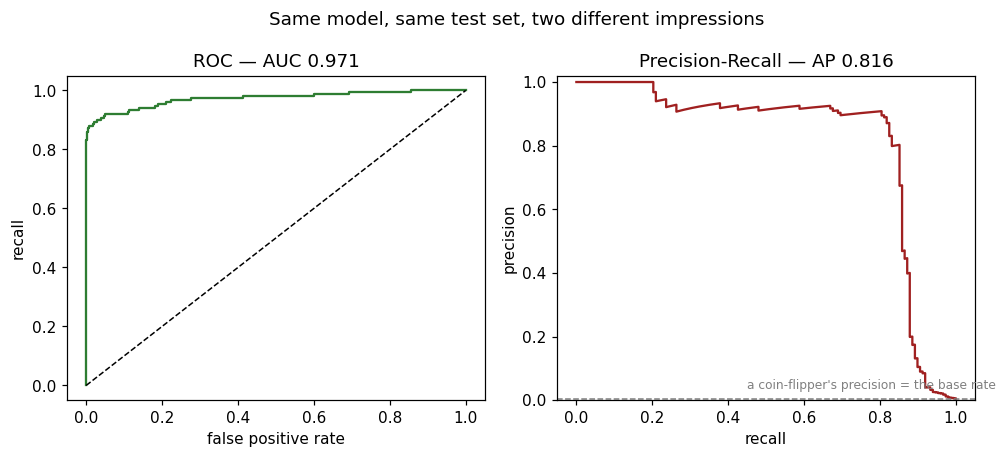

In [33]:
prec_c, rec_c, _ = precision_recall_curve(yte_f, p_fraud)
fpr_c, tpr_c, _  = roc_curve(yte_f, p_fraud)

fig, ax = plt.subplots(1, 2, figsize=(9.5, 4.2))
ax[0].plot(fpr_c, tpr_c, color="#2e7d32")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set_title(f"ROC — AUC {roc_auc_score(yte_f, p_fraud):.3f}")
ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("recall")

ax[1].plot(rec_c, prec_c, color="#a02020")
ax[1].axhline(yte_f.mean(), ls="--", lw=1, color="gray")
ax[1].text(0.45, yte_f.mean() + 0.03, "a coin-flipper's precision = the base rate",
           fontsize=8, color="gray")
ax[1].set_title(f"Precision-Recall — AP {ap:.3f}")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_ylim(0, 1.02)
fig.suptitle("Same model, same test set, two different impressions")
plt.tight_layout(); plt.show()

### So which metric? The one that matches the cost

---

F1 weighed precision and recall **equally**. Is that true here? Is letting a
fraud through really worth exactly as much as pestering one honest customer?

Stop guessing. Every row carries the transaction `Amount`, so a missed fraud
has a **specific dollar cost** — the money gone, plus what it costs the bank to
handle the chargeback. A false alarm costs a fixed amount of review time.
Write both down and the metric argument evaporates.

In [34]:
REVIEW_COST = 5.0     # $ to have a human look at one flagged transaction
ADMIN_COST  = 50.0    # $ per fraud that gets through, on top of the money lost

amounts = Xte_f["Amount"].values
truth   = yte_f.values

def total_cost(threshold):
    d      = (p_fraud >= threshold).astype(int)
    missed = (d == 0) & (truth == 1)
    return (amounts[missed].sum()            # the money itself
            + ADMIN_COST * missed.sum()      # cleaning up each one
            + REVIEW_COST * d.sum())         # reviewing everything we flag

grid  = np.linspace(0.0005, 0.95, 400)
costs = np.array([total_cost(t) for t in grid])
best  = grid[costs.argmin()]

print(f"cost at the default threshold 0.50 : ${total_cost(0.50):,.0f}")
print(f"cheapest threshold                 : {best:.4f}")
print(f"cost there                         : ${costs.min():,.0f}")
print(f"saved by moving the threshold      : ${total_cost(0.50) - costs.min():,.0f}")

cost at the default threshold 0.50 : $6,856
cheapest threshold                 : 0.0172
cost there                         : $5,595
saved by moving the threshold      : $1,261


### The cost curve

---

Every threshold has a price. Here is the whole range of them.

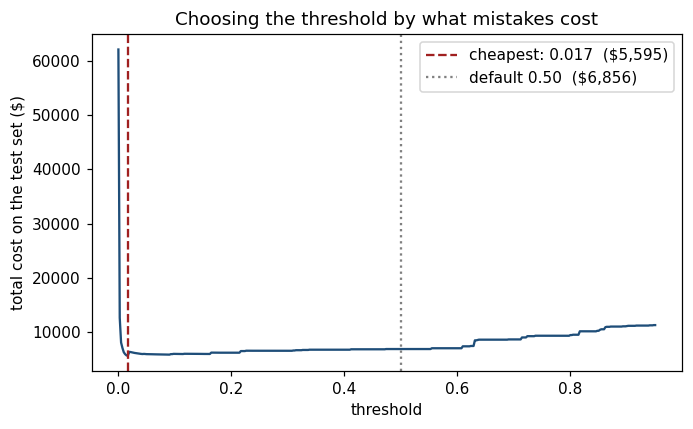

default 0.50 : caught 113 frauds, 12 false alarms
cheapest     : caught 129 frauds, 170 false alarms


In [35]:
d_best = (p_fraud >= best).astype(int)

plt.figure(figsize=(6.4, 4))
plt.plot(grid, costs, color="#1f4e79")
plt.axvline(best, color="#a02020", ls="--",
            label=f"cheapest: {best:.3f}  (${costs.min():,.0f})")
plt.axvline(0.50, color="gray", ls=":",
            label=f"default 0.50  (${total_cost(0.50):,.0f})")
plt.xlabel("threshold"); plt.ylabel("total cost on the test set ($)")
plt.title("Choosing the threshold by what mistakes cost")
plt.legend(); plt.tight_layout(); plt.show()

print(f"default 0.50 : caught {int(((d_fraud==1)&(truth==1)).sum())} frauds, "
      f"{int(((d_fraud==1)&(truth==0)).sum())} false alarms")
print(f"cheapest     : caught {int(((d_best==1)&(truth==1)).sum())} frauds, "
      f"{int(((d_best==1)&(truth==0)).sum())} false alarms")

<span style="color:#1f4e79; font-size:17px">**We did not touch the model.**</span>

Same coefficients, same features, same training data. We moved one number — the
cutoff — and bought a few hundred extra reviews to catch more fraud, because
the arithmetic said those reviews were worth paying for.

Notice that **0.50 was never special.** It is a default that someone chose for
you, and it silently assumes a false alarm and a missed fraud cost the same.
They do not.

### What to take away

---

1. **Accuracy answers a question nobody asked.** With a 99.5% baseline, a model that catches three quarters of the fraud and a model that does nothing are three tenths of a point apart.
2. **The confusion matrix is the primitive.** Precision, recall, F1 and ROC-AUC are arithmetic on its four boxes. Know which box each one ignores.
3. **ROC-AUC ranks models; it does not pick thresholds** — and it flatters rare-class problems. Quote precision-recall instead.
4. **"Which metric?" is really "what does each mistake cost?"** When the data hands you the cost, as `Amount` did, use it and stop arguing about F1.
5. **Change the decision before you change the model.** Threshold tuning is free and keeps probabilities meaningful. Class weights and SMOTE are a different tool for a different problem — making a rare class *learnable*, not making better decisions — and they break your probabilities. See the appendix below before you use them in Project 2.

---

### Additional Content — class weights and SMOTE (not covered in class)

---

*Read this before you reach for either one in Project 2.*

Everything people do about imbalance falls into one of two groups, and they are
routinely confused:

| | what it changes | what it costs you |
|---|---|---|
| **Threshold tuning · cost-weighted metrics** | the **decision** only — the model is untouched | nothing. This is where most of the leverage is. |
| **Class weights · resampling (SMOTE)** | the **model**, and the probabilities it outputs | the probabilities stop being probabilities |

The lecture did the first. This appendix does the second, and shows what it breaks.

In [24]:
clf_w = make_pipeline(StandardScaler(),
                      LogisticRegression(max_iter=1000, class_weight="balanced"))
clf_w.fit(Xtr_f, ytr_f)
p_w = clf_w.predict_proba(Xte_f)[:, 1]
d_w = (p_w >= 0.5).astype(int)

comp = pd.DataFrame({
    "plain @0.50":    [precision_score(yte_f, d_fraud, zero_division=0),
                       recall_score(yte_f, d_fraud),
                       int(d_fraud.sum()), roc_auc_score(yte_f, p_fraud)],
    "weighted @0.50": [precision_score(yte_f, d_w, zero_division=0),
                       recall_score(yte_f, d_w),
                       int(d_w.sum()), roc_auc_score(yte_f, p_w)],
}, index=["precision", "recall", "transactions flagged", "ROC-AUC"])
print(comp.round(3).to_string())

                      plain @0.50  weighted @0.50
precision                   0.904           0.159
recall                      0.764           0.892
transactions flagged      125.000         829.000
ROC-AUC                     0.971           0.975


`class_weight="balanced"` tells the model to treat each fraud as if it were
worth about 100 ordinary transactions. Recall climbs. Precision collapses, and the
number of transactions sent for human review goes up several-fold.

That may be a trade you want. But there is a second effect, and it is the one
people miss.

### What rebalancing broke

---

Bin the predictions and compare what each model *promised* against what
actually happened.

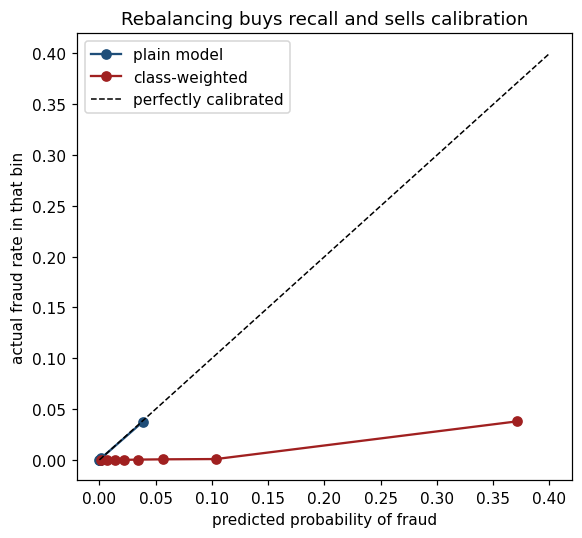

top bin — what each model promised vs what happened:
  plain   : said 0.038, actual 0.037
  weighted: said 0.371, actual 0.038


In [20]:
def calibration(p, y, bins=8):
    edges = np.unique(np.quantile(p, np.linspace(0, 1, bins + 1)))
    idx   = np.digitize(p, edges[1:-1])
    return (pd.DataFrame({"bin": idx, "predicted": p, "actual": y.values})
              .groupby("bin").agg(predicted=("predicted", "mean"),
                                  actual=("actual", "mean")))

fig, ax = plt.subplots(figsize=(5.4, 5))
for p_, lab, c in [(p_fraud, "plain model", "#1f4e79"),
                   (p_w, "class-weighted", "#a02020")]:
    cal = calibration(p_, yte_f)
    ax.plot(cal.predicted, cal.actual, "o-", color=c, label=lab)
ax.plot([0, 0.4], [0, 0.4], "k--", lw=1, label="perfectly calibrated")
ax.set_xlabel("predicted probability of fraud")
ax.set_ylabel("actual fraud rate in that bin")
ax.set_title("Rebalancing buys recall and sells calibration")
ax.legend(); plt.tight_layout(); plt.show()

print("top bin — what each model promised vs what happened:")
for p_, lab in [(p_fraud, "plain   "), (p_w, "weighted")]:
    c = calibration(p_, yte_f).iloc[-1]
    print(f"  {lab}: said {c.predicted:.3f}, actual {c.actual:.3f}")

<span style="color:#a02020">**The weighted model's "probabilities" are no longer
probabilities.**</span> In its most confident bin it says roughly 37% and the
truth is under 4% — off by a factor of ten. The plain model's top bin says 3.8%
and delivers 3.7%.

Remember Tuesday: we praised the professionals' expected-goals model precisely
*because* it was calibrated — when it said 10%, about 10% went in. Reweighting
throws exactly that away.

And it matters practically. The cost rule we just used — *flag it when the
expected loss exceeds the review cost* — *requires* real probabilities to
compute an expected loss. Feed it the weighted model's numbers and the
arithmetic is nonsense.

So:

- Want better **decisions**? Move the threshold. Free, and your probabilities stay honest.
- Want the model to **see** the rare class at all, when it is so rare that training barely registers it? Reweight or resample — then **re-calibrate** before you trust a number again.